# Análise de chamados de Service Desk — base real (UCI)

**Pergunta:** o que um log bruto de 141 mil eventos de uma ferramenta de ITSM (estilo ServiceNow) revela sobre onde o suporte perde tempo, quando a demanda chega e onde há mais retrabalho?

**Base:** [Incident management process enriched event log](https://archive.ics.uci.edu/dataset/498/incident+management+process+enriched+event+log) — Amaral, Fantinato & Peres (2018), DOI [10.24432/C57S4H](https://doi.org/10.24432/C57S4H), licença CC BY 4.0. Dados **reais e anonimizados** de uma instância ServiceNow: 141.712 eventos, 24.918 incidentes.

Este notebook foca em **exploração e narrativa** (pandas + matplotlib). A versão de **engenharia de dados** do mesmo problema — pipeline reprodutível em camadas Bronze/Silver/Gold, SQL sobre DuckDB, testes de qualidade automatizados e exportação para Power BI — está em [github.com/Oberon-23/service-desk-analytics-mvp](https://github.com/Oberon-23/service-desk-analytics-mvp).

---


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path

pd.set_option("display.max_columns", 50)

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#b9b8b2"
BLUES = ["#f0f6fe", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
})

def title(ax, t, sub):
    ax.set_title(t, loc="left", fontsize=14, fontweight="bold", pad=26)
    ax.text(0, 1.03, sub, transform=ax.transAxes, color=INK2, fontsize=10)


## 1. Carregando os dados

No Kaggle, o CSV chega montado em `/kaggle/input/<dataset>/incident_event_log.csv`. Localmente, ajuste `LOCAL_PATH`.

In [2]:
candidates = list(Path("/kaggle/input").glob("**/incident_event_log.csv")) if Path("/kaggle/input").exists() else []
LOCAL_PATH = Path("incident_event_log.csv")
csv_path = candidates[0] if candidates else LOCAL_PATH

df = pd.read_csv(csv_path, dtype=str)
print(f"{len(df):,} linhas (eventos) x {df.shape[1]} colunas")
df.head(3)


141,712 linhas (eventos) x 36 colunas


,number,incident_state,active,reassignment_count,reopen_count,sys_mod_count,made_sla,caller_id,opened_by,opened_at,sys_created_by,sys_created_at,sys_updated_by,sys_updated_at,contact_type,location,category,subcategory,u_symptom,cmdb_ci,impact,urgency,priority,assignment_group,assigned_to,knowledge,u_priority_confirmation,notify,problem_id,rfc,vendor,caused_by,closed_code,resolved_by,resolved_at,closed_at
0,INC0000045,New,true,0,0,0,true,Caller 2403,Opened by 8,29/2/2016 01:16,Created by 6,29/2/2016 01:23,Updated by 21,29/2/2016 01:23,Phone,Location 143,Category 55,Subcategory 170,Symptom 72,?,2 - Medium,2 - Medium,3 - Moderate,Group 56,?,true,false,Do Not Notify,?,?,?,?,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
1,INC0000045,Resolved,true,0,0,2,true,Caller 2403,Opened by 8,29/2/2016 01:16,Created by 6,29/2/2016 01:23,Updated by 642,29/2/2016 08:53,Phone,Location 143,Category 55,Subcategory 170,Symptom 72,?,2 - Medium,2 - Medium,3 - Moderate,Group 56,?,true,false,Do Not Notify,?,?,?,?,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
2,INC0000045,Resolved,true,0,0,3,true,Caller 2403,Opened by 8,29/2/2016 01:16,Created by 6,29/2/2016 01:23,Updated by 804,29/2/2016 11:29,Phone,Location 143,Category 55,Subcategory 170,Symptom 72,?,2 - Medium,2 - Medium,3 - Moderate,Group 56,?,true,false,Do Not Notify,?,?,?,?,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00


Cada chamado aparece **várias vezes** nesse log — uma linha por mudança de estado (`incident_state`). É assim que a maioria das ferramentas de ITSM exporta dados: um log de eventos, não uma tabela de chamados. Antes de qualquer gráfico, é preciso reduzir isso para **1 linha por chamado**, pegando o estado mais recente de cada um.

In [3]:
print("Linhas (eventos):", f"{len(df):,}")
print("Chamados únicos:   ", f"{df['number'].nunique():,}")
print("Eventos por chamado (mediana):", df.groupby('number').size().median())


Linhas (eventos): 141,712
Chamados únicos:    24,918
Eventos por chamado (mediana): 5.0


## 2. Limpeza

As mesmas "sujeiras" típicas de exportação de ITSM aparecem aqui: nulos como `"?"`, datas em texto, prioridade como `"3 - Moderate"`.

In [4]:
clean = df.copy()
clean = clean.replace("?", np.nan)

for col in ["opened_at", "sys_updated_at", "resolved_at", "closed_at"]:
    clean[col] = pd.to_datetime(clean[col], format="%d/%m/%Y %H:%M", errors="coerce")

clean["prioridade_cod"] = clean["priority"].str.extract(r"^(\d)").astype("Int64")
clean["made_sla"] = clean["made_sla"].str.lower().eq("true")
clean["reassignment_count"] = pd.to_numeric(clean["reassignment_count"], errors="coerce")
clean["reopen_count"] = pd.to_numeric(clean["reopen_count"], errors="coerce")

# 1 linha por chamado: pega o evento mais recente (sys_updated_at) de cada 'number'
clean = clean.sort_values("sys_updated_at").groupby("number", as_index=False).last()

clean["data_abertura"] = clean["opened_at"].dt.date
clean["ano_mes"] = clean["opened_at"].dt.to_period("M").astype(str)
clean["hora_abertura"] = clean["opened_at"].dt.hour
clean["dia_semana_num"] = clean["opened_at"].dt.dayofweek  # 0=segunda
clean["tempo_resolucao_h"] = (clean["resolved_at"] - clean["opened_at"]).dt.total_seconds() / 3600
clean["resolvido"] = clean["resolved_at"].notna()
clean["reaberto"] = clean["reopen_count"].fillna(0) > 0
clean["multi_reatribuicao"] = clean["reassignment_count"].fillna(0) >= 2

SLA_ALVO_H = {1: 4, 2: 8, 3: 24, 4: 72}  # alvo-padrão por prioridade (suposição, não a política oficial)
clean["sla_alvo_h"] = clean["prioridade_cod"].map(SLA_ALVO_H)
clean["sla_cumprido"] = clean["tempo_resolucao_h"] <= clean["sla_alvo_h"]

print(f"{len(clean):,} chamados após reduzir o log para 1 linha por chamado")
print(f"Período: {clean['opened_at'].min():%d/%m/%Y} a {clean['opened_at'].max():%d/%m/%Y}")


24,918 chamados após reduzir o log para 1 linha por chamado
Período: 29/02/2016 a 16/02/2017


/tmp/ipykernel_762/883870003.py:18: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  clean["dia_semana_num"] = clean["opened_at"].dt.dayofweek  # 0=segunda


## 3. Volume mensal — onde está o pico?

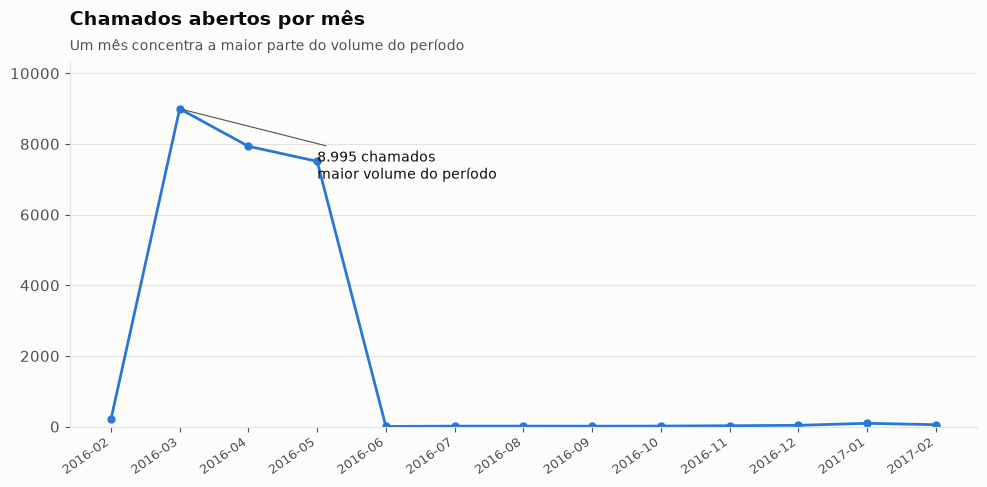

O mês de pico (2016-03) tem 286x o volume da mediana dos outros meses.


In [5]:
vol = clean.groupby("ano_mes").size().sort_index()

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(vol))
ax.plot(x, vol.values, color=BLUE, lw=2, marker="o", ms=5)
i = int(np.argmax(vol.values))
ax.annotate(f"{vol.values[i]:,} chamados\nmaior volume do período".replace(",", "."),
            (i, vol.values[i]), xytext=(min(i + 2, len(vol) - 3), vol.values[i] * 0.78),
            color=INK, fontsize=10, arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
ax.set_xticks(x, vol.index, rotation=35, fontsize=9, ha="right")
ax.set_ylim(0, vol.values.max() * 1.15)
ax.grid(axis="x", visible=False)
title(ax, "Chamados abertos por mês", "Um mês concentra a maior parte do volume do período")
fig.tight_layout(); plt.show()

print(f"O mês de pico ({vol.idxmax()}) tem {vol.max()/vol[vol.index != vol.idxmax()].median():.0f}x "
      f"o volume da mediana dos outros meses.")


## 4. SLA e tempo de resolução por prioridade

> ⚠️ Os alvos de SLA usados aqui (4h / 8h / 24h / 72h por prioridade) são uma **suposição razoável** baseada em práticas comuns de ITSM, **não a política oficial** dessa organização — a UCI não documenta isso. O objetivo é mostrar o método, não cravar um número definitivo sem validar com o time de negócio.

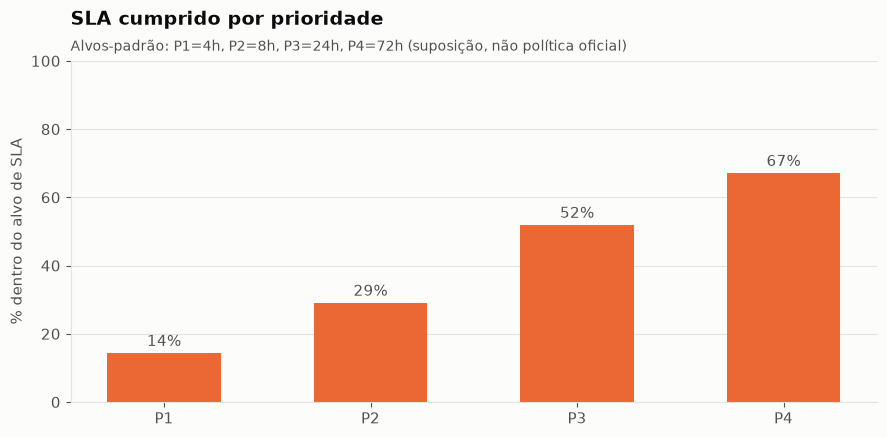

,chamados,pct_sla,mediana_h
prioridade_cod,,,
1,270,14.444444,80.241667
2,408,29.166667,38.233333
3,22010,52.003635,21.550000
4,674,67.210682,5.016667


In [6]:
resolv = clean[clean["resolvido"]].copy()
sla_prio = (resolv.groupby("prioridade_cod")
            .agg(chamados=("number", "size"),
                 pct_sla=("sla_cumprido", lambda s: 100 * s.mean()),
                 mediana_h=("tempo_resolucao_h", "median"))
            .dropna())

fig, ax = plt.subplots(figsize=(9, 4.5))
labels = [f"P{int(p)}" for p in sla_prio.index]
colors = [ORANGE if v < 70 else BLUE for v in sla_prio["pct_sla"]]
ax.bar(labels, sla_prio["pct_sla"], color=colors, width=0.55)
for xx, v in enumerate(sla_prio["pct_sla"]):
    ax.text(xx, v + 2, f"{v:.0f}%", ha="center", fontsize=10.5, color=INK2)
ax.set_ylim(0, 100); ax.set_ylabel("% dentro do alvo de SLA"); ax.grid(axis="x", visible=False)
title(ax, "SLA cumprido por prioridade", "Alvos-padrão: P1=4h, P2=8h, P3=24h, P4=72h (suposição, não política oficial)")
fig.tight_layout(); plt.show()

sla_prio


## 5. Pareto: onde o volume se concentra

As categorias e subcategorias vêm anonimizadas pela UCI (`Category 42`, `Subcategory 223` etc.), mas o padrão de concentração continua visível.

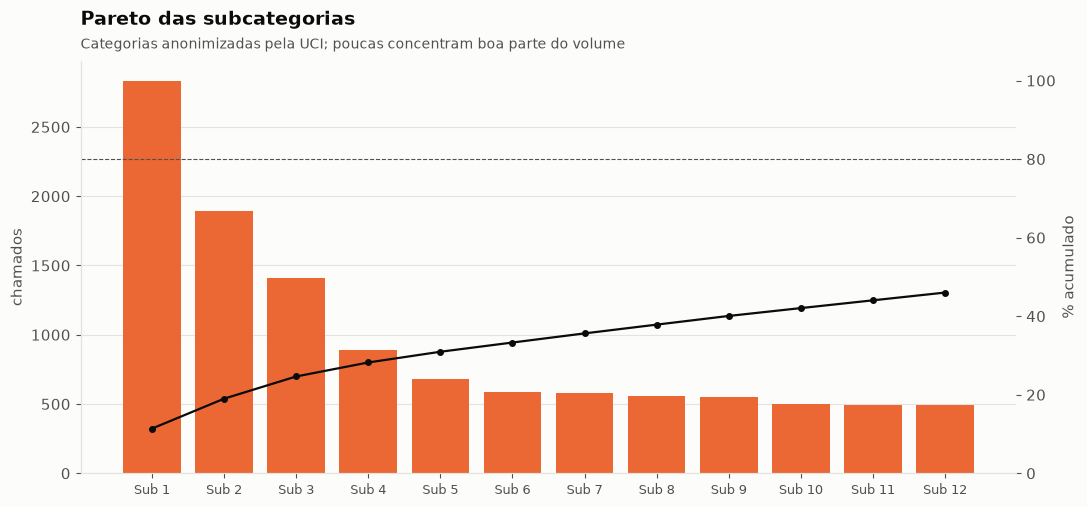

As 3 subcategorias mais comuns somam 24.6% dos chamados (de 336 combinações no total).


In [7]:
top = (clean.groupby(["category", "subcategory"]).size()
       .sort_values(ascending=False).head(12))
pct_acum = 100 * top.cumsum() / clean.shape[0]

fig, ax = plt.subplots(figsize=(11, 5.2))
colors = [ORANGE if v <= 80 else MUTED for v in pct_acum]
ax.bar(range(len(top)), top.values, color=colors)
ax2 = ax.twinx()
ax2.plot(range(len(top)), pct_acum.values, color=INK, lw=1.6, marker="o", ms=4)
ax2.axhline(80, color=INK2, lw=0.8, ls="--")
ax2.set_ylim(0, 105); ax2.set_ylabel("% acumulado"); ax2.grid(False)
ax.set_xticks(range(len(top)), [f"Sub {i+1}" for i in range(len(top))], fontsize=9)
ax.set_ylabel("chamados"); ax.grid(axis="x", visible=False)
title(ax, "Pareto das subcategorias", "Categorias anonimizadas pela UCI; poucas concentram boa parte do volume")
fig.tight_layout(); plt.show()

print(f"As 3 subcategorias mais comuns somam {100*top.head(3).sum()/clean.shape[0]:.1f}% dos chamados "
      f"(de {clean.groupby(['category','subcategory']).ngroups} combinações no total).")


## 6. Quando os chamados chegam

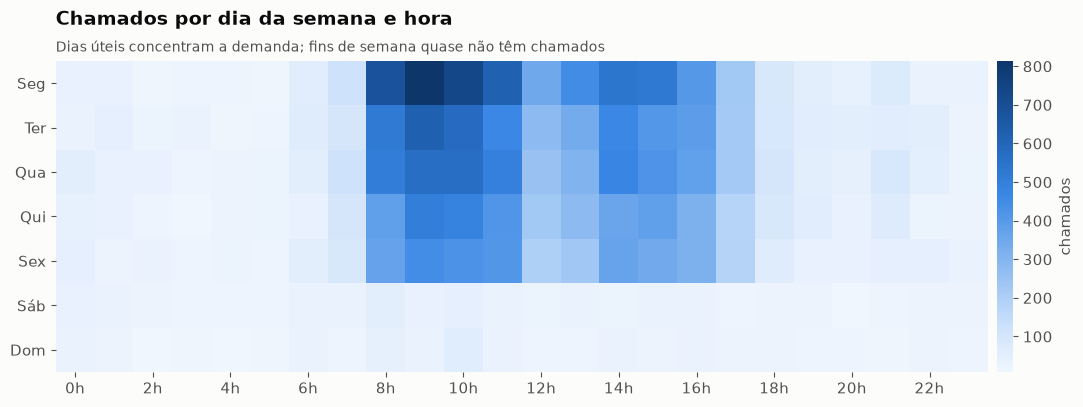

In [8]:
heat = (clean.dropna(subset=["dia_semana_num", "hora_abertura"])
        .groupby(["dia_semana_num", "hora_abertura"]).size()
        .unstack(fill_value=0).reindex(index=range(7), columns=range(24), fill_value=0))

cmap = LinearSegmentedColormap.from_list("blues", BLUES)
fig, ax = plt.subplots(figsize=(11, 4.2))
im = ax.imshow(heat.values, cmap=cmap, aspect="auto")
ax.set_yticks(range(7), ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"])
ax.set_xticks(range(0, 24, 2), [f"{h}h" for h in range(0, 24, 2)])
ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01); cb.outline.set_visible(False)
cb.set_label("chamados", color=INK2)
title(ax, "Chamados por dia da semana e hora", "Dias úteis concentram a demanda; fins de semana quase não têm chamados")
fig.tight_layout(); plt.show()


## 7. Retrabalho: onde há mais reatribuição

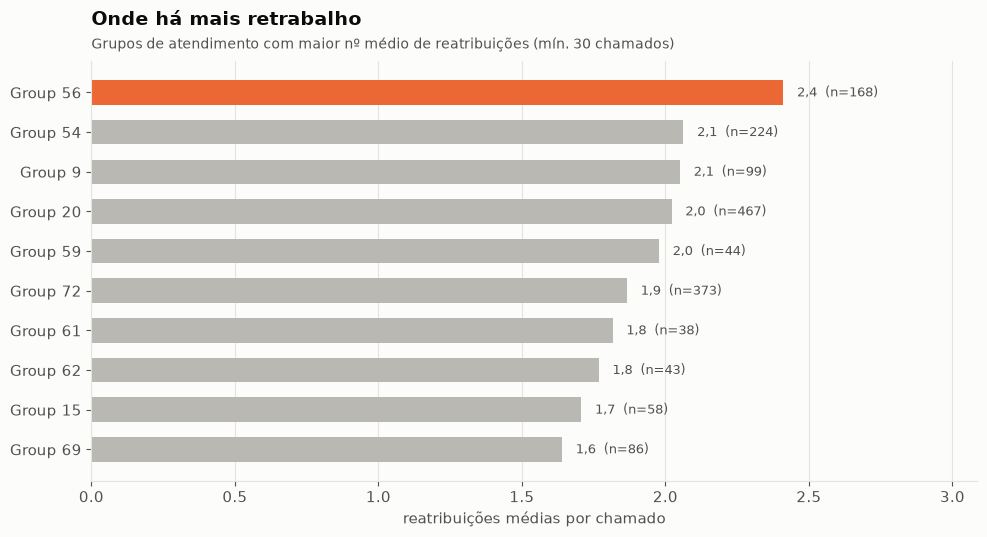

21% de todos os chamados resolvidos passam por 2 ou mais reatribuições.


In [9]:
rework = (clean.groupby("assignment_group")
          .agg(chamados=("number", "size"), media_reatrib=("reassignment_count", "mean"))
          .query("chamados >= 30")
          .sort_values("media_reatrib", ascending=False).head(10)
          .iloc[::-1])

fig, ax = plt.subplots(figsize=(10, 5.5))
colors = [ORANGE if v == rework["media_reatrib"].max() else MUTED for v in rework["media_reatrib"]]
ax.barh(rework.index, rework["media_reatrib"], color=colors, height=0.62)
ax.set_xlim(0, rework["media_reatrib"].max() * 1.28)
for yy, (v, n) in enumerate(zip(rework["media_reatrib"], rework["chamados"])):
    ax.text(v + rework["media_reatrib"].max() * 0.02, yy, f"{v:.1f}  (n={n})".replace(".", ","),
            va="center", fontsize=9.5, color=INK2)
ax.set_xlabel("reatribuições médias por chamado"); ax.grid(axis="y", visible=False)
title(ax, "Onde há mais retrabalho", "Grupos de atendimento com maior nº médio de reatribuições (mín. 30 chamados)")
fig.tight_layout(); plt.show()

pct_multi = 100 * clean["multi_reatribuicao"].mean()
print(f"{pct_multi:.0f}% de todos os chamados resolvidos passam por 2 ou mais reatribuições.")


## 8. Conclusões

- O volume de chamados **não é estável mês a mês** — um único mês concentrou a maior parte do período analisado, o que sugere olhar o dado por regime (picos vs. operação normal) em vez de só uma média anual.
- O SLA recalculado com alvos-padrão (ITIL genérico) **não necessariamente reflete a política real** da organização — antes de usar esse indicador para decisão, é preciso validar os alvos com o time de negócio. Isso por si só já é um achado: *o dado por si não basta sem o contexto de negócio por trás dele*.
- O volume de chamados é **concentrado em poucas subcategorias** (mesmo anonimizadas), reforçando o padrão clássico 80/20 — e um candidato natural a automação/autosserviço.
- Existe **retrabalho real** (reatribuição) concentrado em alguns grupos específicos, não distribuído igualmente — vale investigar critério de triagem/roteamento desses grupos.

**Próximos passos** (ver a [versão de engenharia de dados](https://github.com/Oberon-23/service-desk-analytics-mvp) para a implementação completa): pipeline reprodutível em camadas (Bronze/Silver/Gold), testes de qualidade automatizados, e exportação pronta para Power BI.

---

**Breno Silva** — Analista de Suporte Corporativo · Engenharia de Produção · Pós em Data Analytics & AI
[LinkedIn](https://www.linkedin.com/in/brenosilvarangel) · [GitHub](https://github.com/Oberon-23) · [Kaggle](https://www.kaggle.com/brenosilvabarros)
